
========== Data Analysis & Visualization Program ==========
1. Load Dataset
2. Explore Data
3. Perform DataFrame Operations
4. Handle Missing Data
5. Generate Descriptive Statistics
6. Data Visualization
7. Save Visualization
8. Exit



Dataset loaded successfully!
Total Records: 5
Total Columns: 6

=== Explore Data ===
1. Display first 5 rows
2. Display last 5 rows
3. Display column names
4. Display data types
5. Display basic information
6. Return to main menu
   SalesID     Product   Region  Sales  Year Unnamed: 5
0      101   Product A    North    500  2022    py.pro9
1      102   Product B     East    600  2022        NaN
2      103  Product C      West    700  2022        NaN
3      104  Product D     South    800  2022        NaN
4      105   Product E  Central    550  2022        NaN

=== Explore Data ===
1. Display first 5 rows
2. Display last 5 rows
3. Display column names
4. Display data types
5. Display basic information
6. Return to main menu
   SalesID     Product   Region  Sales  Year Unnamed: 5
0      101   Product A    North    500  2022    py.pro9
1      102   Product B     East    600  2022        NaN
2      103  Product C      West    700  2022        NaN
3      104  Product D     South    800  20

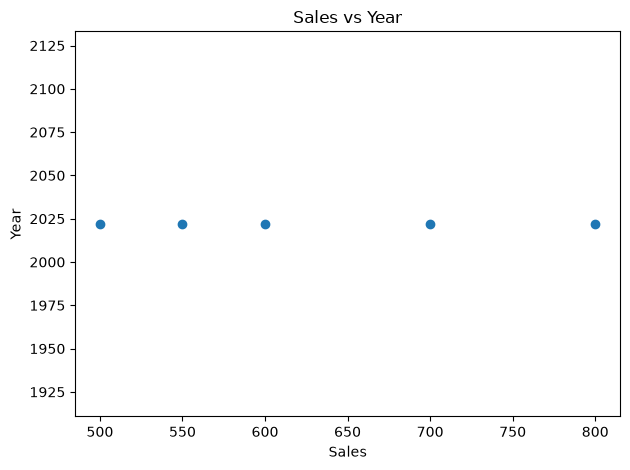


========== Data Analysis & Visualization Program ==========
1. Load Dataset
2. Explore Data
3. Perform DataFrame Operations
4. Handle Missing Data
5. Generate Descriptive Statistics
6. Data Visualization
7. Save Visualization
8. Exit
Invalid numeric column.

========== Data Analysis & Visualization Program ==========
1. Load Dataset
2. Explore Data
3. Perform DataFrame Operations
4. Handle Missing Data
5. Generate Descriptive Statistics
6. Data Visualization
7. Save Visualization
8. Exit
Invalid numeric column.

========== Data Analysis & Visualization Program ==========
1. Load Dataset
2. Explore Data
3. Perform DataFrame Operations
4. Handle Missing Data
5. Generate Descriptive Statistics
6. Data Visualization
7. Save Visualization
8. Exit
Invalid numeric column.

========== Data Analysis & Visualization Program ==========
1. Load Dataset
2. Explore Data
3. Perform DataFrame Operations
4. Handle Missing Data
5. Generate Descriptive Statistics
6. Data Visualization
7. Save Visualizat

In [20]:
# -----------------------------
# PANDAS & DATA VISUALIZATION
# -----------------------------
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


class SalesDataAnalyzer:

    def __init__(self):
        self.data = None

    # 1. Load Dataset
    def load_data(self):
        filename = input("Enter CSV file path: ").strip()

        try:
            self.data = pd.read_csv(filename)
            print("\nDataset loaded successfully!")
            print("Total Records:", len(self.data))
            print("Total Columns:", len(self.data.columns))
            self.explore_data()

        except FileNotFoundError:
            print("Error: File not found.")
        except Exception as e:
            print("Error loading dataset:", e)

    # 2. Explore Dataset
    def explore_data(self):
        if self.data is None:
            print("Please load a dataset first.")
            return

        while True:
            print("\n=== Explore Data ===")
            print("1. Display first 5 rows")
            print("2. Display last 5 rows")
            print("3. Display column names")
            print("4. Display data types")
            print("5. Display basic information")
            print("6. Return to main menu")

            choice = input("Enter your choice: ")

            if choice == "1":
                print(self.data.head())
            elif choice == "2":
                print(self.data.tail())
            elif choice == "3":
                print(self.data.columns.tolist())
            elif choice == "4":
                print(self.data.dtypes)
            elif choice == "5":
                self.data.info()
                print("\nMissing Values:\n", self.data.isnull().sum())
                print("\nStatistics:\n", self.data.describe(include="all"))
            elif choice == "6":
                break
            else:
                print("Invalid choice.")

    # 3. Handle Missing Data and Clean Dataset
    def clean_data(self):
        if self.data is None:
            print("Please load a dataset first.")
            return

        print("\nMissing values before cleaning:")
        print(self.data.isnull().sum())

        for column in self.data.columns:
            if self.data[column].isnull().any():
                if pd.api.types.is_numeric_dtype(self.data[column]):
                    self.data[column] = self.data[column].fillna(
                        self.data[column].mean()
                    )
                else:
                    mode = self.data[column].mode()
                    if not mode.empty:
                        self.data[column] = self.data[column].fillna(
                            mode.iloc[0]
                        )
                    else:
                        self.data[column] = self.data[column].fillna("Unknown")

        duplicates = self.data.duplicated().sum()
        self.data.drop_duplicates(inplace=True)

        print("\nDataset cleaned successfully!")
        print("Duplicate rows removed:", duplicates)
        print("\nMissing values after cleaning:")
        print(self.data.isnull().sum())

    # 4. Mathematical Operations
    def mathematical_operations(self):
        if self.data is None:
            print("Please load a dataset first.")
            return

        numeric = self.data.select_dtypes(include=np.number)

        if numeric.empty:
            print("No numeric columns found.")
            return

        print("\n=== Mathematical Operations ===")
        print("1. Add a value")
        print("2. Multiply by a value")
        print("3. Square numeric values")
        print("4. Matrix multiplication / dot product")

        choice = input("Enter your choice: ")

        if choice in ["1", "2", "3"]:
            column = input("Enter numeric column name: ")

            if column not in numeric.columns:
                print("Invalid numeric column.")
                return

            if choice == "1":
                value = float(input("Enter value to add: "))
                print(self.data[column] + value)

            elif choice == "2":
                value = float(input("Enter multiplier: "))
                print(self.data[column] * value)

            else:
                print(np.square(self.data[column]))

        elif choice == "4":
            print("Available numeric columns:", numeric.columns.tolist())

            col1 = input("Enter first column: ")
            col2 = input("Enter second column: ")

            if col1 in numeric.columns and col2 in numeric.columns:
                result = np.dot(
                    numeric[col1].to_numpy(),
                    numeric[col2].to_numpy()
                )
                print("Dot Product:", result)
            else:
                print("Invalid column names.")
        else:
            print("Invalid choice.")

    # 5. Combine and Split DataFrames
    def combine_split_data(self):
        if self.data is None:
            print("Please load a dataset first.")
            return

        print("\n=== Combine / Split Data ===")
        print("1. Split dataset into two parts")
        print("2. Combine another CSV file")
        print("3. Display dataset shape")

        choice = input("Enter your choice: ")

        if choice == "1":
            midpoint = len(self.data) // 2
            first = self.data.iloc[:midpoint]
            second = self.data.iloc[midpoint:]

            first.to_csv("data_part1.csv", index=False)
            second.to_csv("data_part2.csv", index=False)

            print("Saved data_part1.csv and data_part2.csv")

        elif choice == "2":
            filename = input("Enter second CSV file path: ")

            try:
                other = pd.read_csv(filename)

                print("1. Combine rows")
                print("2. Combine columns")
                method = input("Enter choice: ")

                if method == "1":
                    self.data = pd.concat(
                        [self.data, other], ignore_index=True
                    )
                elif method == "2":
                    if len(self.data) != len(other):
                        print("Both datasets must have equal row counts.")
                        return

                    other = other.reset_index(drop=True)
                    self.data = pd.concat(
                        [self.data.reset_index(drop=True), other],
                        axis=1
                    )
                else:
                    print("Invalid choice.")
                    return

                print("Datasets combined successfully.")
                print(self.data.head())

            except Exception as e:
                print("Error:", e)

        elif choice == "3":
            print("Shape:", self.data.shape)

        else:
            print("Invalid choice.")

    # 6. Search, Sort and Filter
    def search_sort_filter(self):
        if self.data is None:
            print("Please load a dataset first.")
            return

        print("\n=== Search, Sort and Filter ===")
        print("1. Search for a value")
        print("2. Sort by a column")
        print("3. Filter numeric values")

        choice = input("Enter your choice: ")

        if choice == "1":
            column = input("Enter column name: ")
            value = input("Enter search value: ")

            if column not in self.data.columns:
                print("Column not found.")
                return

            result = self.data[
                self.data[column].astype(str).str.contains(
                    value, case=False, na=False
                )
            ]
            print(result)

        elif choice == "2":
            column = input("Enter column to sort by: ")

            if column not in self.data.columns:
                print("Column not found.")
                return

            order = input("Ascending? (y/n): ").lower() == "y"
            print(self.data.sort_values(column, ascending=order))

        elif choice == "3":
            numeric = self.data.select_dtypes(include=np.number)
            column = input("Enter numeric column: ")

            if column not in numeric.columns:
                print("Numeric column not found.")
                return

            try:
                value = float(input("Show values greater than: "))
                print(self.data[self.data[column] > value])
            except ValueError:
                print("Please enter a valid number.")

        else:
            print("Invalid choice.")

    # 7. Aggregation Functions
    def aggregate_functions(self):
        if self.data is None:
            print("Please load a dataset first.")
            return

        numeric = self.data.select_dtypes(include=np.number)

        if numeric.empty:
            print("No numeric columns found.")
            return

        print("\n=== Aggregate Functions ===")
        print("1. Sum")
        print("2. Mean")
        print("3. Minimum")
        print("4. Maximum")
        print("5. Count")
        print("6. Group by category")

        choice = input("Enter your choice: ")

        if choice in ["1", "2", "3", "4", "5"]:
            column = input("Enter numeric column: ")

            if column not in numeric.columns:
                print("Invalid numeric column.")
                return

            if choice == "1":
                print("Sum:", numeric[column].sum())
            elif choice == "2":
                print("Mean:", numeric[column].mean())
            elif choice == "3":
                print("Minimum:", numeric[column].min())
            elif choice == "4":
                print("Maximum:", numeric[column].max())
            elif choice == "5":
                print("Count:", numeric[column].count())

        elif choice == "6":
            category = input("Enter category column: ")
            value_column = input("Enter numeric column: ")

            if category in self.data.columns and value_column in numeric.columns:
                print(
                    self.data.groupby(category)[value_column]
                    .agg(["sum", "mean", "count"])
                )
            else:
                print("Invalid column names.")

        else:
            print("Invalid choice.")

    # 8. Statistical Analysis
    def statistical_analysis(self):
        if self.data is None:
            print("Please load a dataset first.")
            return

        numeric = self.data.select_dtypes(include=np.number)

        print("\n=== Statistical Analysis ===")
        print("1. Descriptive statistics")
        print("2. Standard deviation")
        print("3. Variance")
        print("4. Percentiles")
        print("5. Correlation matrix")

        choice = input("Enter your choice: ")

        if choice == "1":
            print(numeric.describe())
        elif choice == "2":
            print(numeric.std())
        elif choice == "3":
            print(numeric.var())
        elif choice == "4":
            print(numeric.quantile([0.25, 0.50, 0.75]))
        elif choice == "5":
            print(numeric.corr())
        else:
            print("Invalid choice.")

    # 9. Pivot Table
    def create_pivot_table(self):
        if self.data is None:
            print("Please load a dataset first.")
            return

        print("Available columns:", self.data.columns.tolist())

        index_col = input("Enter grouping/index column: ")
        value_col = input("Enter numeric value column: ")

        if index_col not in self.data.columns:
            print("Invalid index column.")
            return

        if value_col not in self.data.columns:
            print("Invalid value column.")
            return

        if not pd.api.types.is_numeric_dtype(self.data[value_col]):
            print("Value column must be numeric.")
            return

        print(pd.pivot_table(
            self.data,
            index=index_col,
            values=value_col,
            aggfunc=["sum", "mean", "count"]
        ))

    # 10. Data Visualization
    def visualize_data(self):
        if self.data is None:
            print("Please load a dataset first.")
            return

        numeric = self.data.select_dtypes(include=np.number)

        if numeric.empty:
            print("No numeric columns available for plotting.")
            return

        print("\n=== Data Visualization ===")
        print("1. Bar chart")
        print("2. Line chart")
        print("3. Scatter plot")
        print("4. Pie chart")
        print("5. Histogram")
        print("6. Box plot")
        print("7. Heatmap")
        print("8. Pair plot")

        choice = input("Enter your choice: ")

        if choice in ["1", "2", "5", "6"]:
            column = input("Enter numeric column: ")

            if column not in numeric.columns:
                print("Invalid numeric column.")
                return

            if choice == "1":
                self.data[column].plot(kind="bar", figsize=(8, 5))
                plt.title(f"Bar Chart of {column}")

            elif choice == "2":
                self.data[column].reset_index(drop=True).plot(
                    kind="line", figsize=(8, 5)
                )
                plt.title(f"Line Chart of {column}")

            elif choice == "5":
                self.data[column].plot(kind="hist", bins=10, figsize=(8, 5))
                plt.title(f"Histogram of {column}")

            elif choice == "6":
                sns.boxplot(x=self.data[column])
                plt.title(f"Box Plot of {column}")

        elif choice == "3":
            columns = numeric.columns.tolist()

            if len(columns) < 2:
                print("At least two numeric columns are required.")
                return

            x = input("Enter X-axis column: ")
            y = input("Enter Y-axis column: ")

            if x not in numeric.columns or y not in numeric.columns:
                print("Invalid numeric columns.")
                return

            plt.scatter(self.data[x], self.data[y])
            plt.xlabel(x)
            plt.ylabel(y)
            plt.title(f"{x} vs {y}")

        elif choice == "4":
            category = input("Enter category column: ")

            if category not in self.data.columns:
                print("Column not found.")
                return

            counts = self.data[category].value_counts().head(10)
            counts.plot(kind="pie", autopct="%1.1f%%")
            plt.title(f"Distribution of {category}")
            plt.ylabel("")

        elif choice == "7":
            plt.figure(figsize=(9, 6))
            sns.heatmap(numeric.corr(), annot=True, cmap="coolwarm")
            plt.title("Correlation Heatmap")

        elif choice == "8":
            if len(numeric.columns) < 2:
                print("At least two numeric columns are required.")
                return

            sns.pairplot(numeric)
            plt.show()
            return

        else:
            print("Invalid choice.")
            return

        plt.tight_layout()
        plt.show()

    # 11. Save Visualization
    def save_visualization(self):
        if self.data is None:
            print("Please load a dataset first.")
            return

        numeric = self.data.select_dtypes(include=np.number)

        if numeric.empty:
            print("No numeric columns available.")
            return

        column = input("Enter numeric column to plot: ")

        if column not in numeric.columns:
            print("Invalid numeric column.")
            return

        filename = input("Enter image filename (e.g. sales.png): ").strip()

        if not filename:
            filename = "visualization.png"

        if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
            print("Use a .png, .jpg, or .jpeg filename.")
            return

        numeric[column].plot(kind="line", figsize=(8, 5))
        plt.title(f"{column} Visualization")
        plt.xlabel("Index")
        plt.ylabel(column)
        plt.tight_layout()

        try:
            plt.savefig(filename, dpi=300, bbox_inches="tight")
            print("Visualization saved as:", os.path.abspath(filename))
        except Exception as e:
            print("Error saving visualization:", e)
        finally:
            plt.close()

    # 12. Main Menu
    def run(self):
        while True:
            print("\n========== Data Analysis & Visualization Program ==========")
            print("1. Load Dataset")
            print("2. Explore Data")
            print("3. Perform DataFrame Operations")
            print("4. Handle Missing Data")
            print("5. Generate Descriptive Statistics")
            print("6. Data Visualization")
            print("7. Save Visualization")
            print("8. Exit")

            choice = input("Please select an option: ")

            if choice == "1":
                self.load_data()

            elif choice == "2":
                self.explore_data()

            elif choice == "3":
                while True:
                    print("\n=== DataFrame Operations ===")
                    print("1. Mathematical Operations")
                    print("2. Combine or Split Data")
                    print("3. Search, Sort or Filter")
                    print("4. Aggregation Functions")
                    print("5. Create Pivot Table")
                    print("6. Return to Main Menu")

                    sub = input("Enter your choice: ")

                    if sub == "1":
                        self.mathematical_operations()
                    elif sub == "2":
                        self.combine_split_data()
                    elif sub == "3":
                        self.search_sort_filter()
                    elif sub == "4":
                        self.aggregate_functions()
                    elif sub == "5":
                        self.create_pivot_table()
                    elif sub == "6":
                        break
                    else:
                        print("Invalid choice.")

            elif choice == "4":
                self.clean_data()

            elif choice == "5":
                self.statistical_analysis()

            elif choice == "6":
                self.visualize_data()

            elif choice == "7":
                self.save_visualization()

            elif choice == "8":
                print("Thank you for using Pandas Analyzer!")
                break

            else:
                print("Invalid choice. Please try again.")


if __name__ == "__main__":
    analyzer = SalesDataAnalyzer()
    analyzer.run()